# Microproyecto CNN — Clasificación de imágenes MRI cerebrales

## 1. Importaciones y rutas

In [1]:
from pathlib import Path
from collections import Counter
import random
import zipfile
import shutil

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Configuración general
SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 15
CLASES = ["glioma", "healthy", "meningioma", "pituitary"]
NUM_CLASES = len(CLASES)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# La ubicación está basada en tu carpeta: Escritorio/Proyecto_CNN
BASE = Path.home() / "OneDrive" / "Documents" / "Uniandes Maestria" / "Ciclo 4" / "Deep learning" / "Modulo 3" / "Miniproyecto 1"
RUTA_ZIP = BASE / "archive.zip"
DIR_DATOS = BASE / "datos_mri"
DIR_RESULTADOS = BASE / "resultados"

print("TensorFlow:", tf.__version__)
print("Carpeta del proyecto:", BASE)
print("ZIP:", RUTA_ZIP)
print("¿ZIP encontrado?:", RUTA_ZIP.is_file())
print("GPU(s):", tf.config.list_physical_devices("GPU"))

if not RUTA_ZIP.is_file():
    raise FileNotFoundError(
        f"No se encontró el archivo ZIP en {RUTA_ZIP}. "
        "Revisa el nombre archive.zip y su ubicación. "
        "Si el ZIP está en otra carpeta, modifica solamente BASE en esta celda."
    )

DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)


TensorFlow: 2.21.0
Carpeta del proyecto: C:\Users\user\OneDrive\Documents\Uniandes Maestria\Ciclo 4\Deep learning\Modulo 3\Miniproyecto 1
ZIP: C:\Users\user\OneDrive\Documents\Uniandes Maestria\Ciclo 4\Deep learning\Modulo 3\Miniproyecto 1\archive.zip
¿ZIP encontrado?: True
GPU(s): []


In [2]:
with zipfile.ZipFile(RUTA_ZIP) as z:
    archivos = [m.filename for m in z.infolist() if not m.is_dir()]

print("Total de archivos:", len(archivos))
print("Niveles de ruta:", Counter(len(Path(f).parts) for f in archivos))
print("Extensiones:", Counter(Path(f).suffix.lower() for f in archivos))
print("Ejemplos:", archivos[:5])

Total de archivos: 7023
Niveles de ruta: Counter({2: 7023})
Extensiones: Counter({'.jpg': 7023})
Ejemplos: ['glioma/0000.jpg', 'glioma/0001.jpg', 'glioma/0002.jpg', 'glioma/0003.jpg', 'glioma/0004.jpg']


## 2. Extraer imágenes y crear `rutas` y `etiquetas`

Distribución esperada: glioma 1.621 · healthy 2.000 · meningioma 1.645 · pituitary 1.757 (total: 7.023).

In [3]:
CANTIDADES_ESPERADAS = {
    "glioma": 1621,
    "healthy": 2000,
    "meningioma": 1645,
    "pituitary": 1757,
}

def carpetas_completas():
    return all(
        (DIR_DATOS / clase).is_dir()
        and sum(1 for _ in (DIR_DATOS / clase).glob("*.jpg")) == cantidad
        for clase, cantidad in CANTIDADES_ESPERADAS.items()
    )

if not carpetas_completas():
    print("Extrayendo imágenes desde el ZIP...")
    DIR_DATOS.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(RUTA_ZIP, "r") as archivo:
        for miembro in archivo.infolist():
            ruta = Path(miembro.filename)
            # Extraer únicamente archivos .jpg dentro de una carpeta de clase
            if (
                not miembro.is_dir()
                and len(ruta.parts) == 2
                and ruta.parts[0] in CLASES
                and ruta.suffix.lower() == ".jpg"
            ):
                destino = DIR_DATOS / ruta.parts[0] / ruta.name
                destino.parent.mkdir(parents=True, exist_ok=True)
                with archivo.open(miembro) as origen, destino.open("wb") as salida:
                    shutil.copyfileobj(origen, salida)
    print("Extracción finalizada.")
else:
    print("Las imágenes ya estaban extraídas; no se repite el proceso.")

rutas, etiquetas = [], []
for indice, clase in enumerate(CLASES):
    imagenes = sorted((DIR_DATOS / clase).glob("*.jpg"))
    cantidad = CANTIDADES_ESPERADAS[clase]
    if len(imagenes) != cantidad:
        raise RuntimeError(
            f"Se encontraron {len(imagenes)} imágenes de {clase}, "
            f"pero se esperaban {cantidad}. Revisa la extracción."
        )
    rutas.extend(str(ruta) for ruta in imagenes)
    etiquetas.extend([indice] * len(imagenes))
    print(f"{clase:12s}: {len(imagenes)} imágenes")

rutas = np.asarray(rutas)
etiquetas = np.asarray(etiquetas, dtype=np.int32)

print(f"\nTotal de imágenes: {len(rutas)}")
assert len(rutas) == 7023, "El dataset debe contener 7.023 imágenes."
print("Variables listas: rutas y etiquetas")


Extrayendo imágenes desde el ZIP...
Extracción finalizada.
glioma      : 1621 imágenes
healthy     : 2000 imágenes
meningioma  : 1645 imágenes
pituitary   : 1757 imágenes

Total de imágenes: 7023
Variables listas: rutas y etiquetas


## 3. Visualizar ejemplos

Mostramos dos imágenes de cada clase. Las distintas dimensiones originales se adaptarán al entrenar.

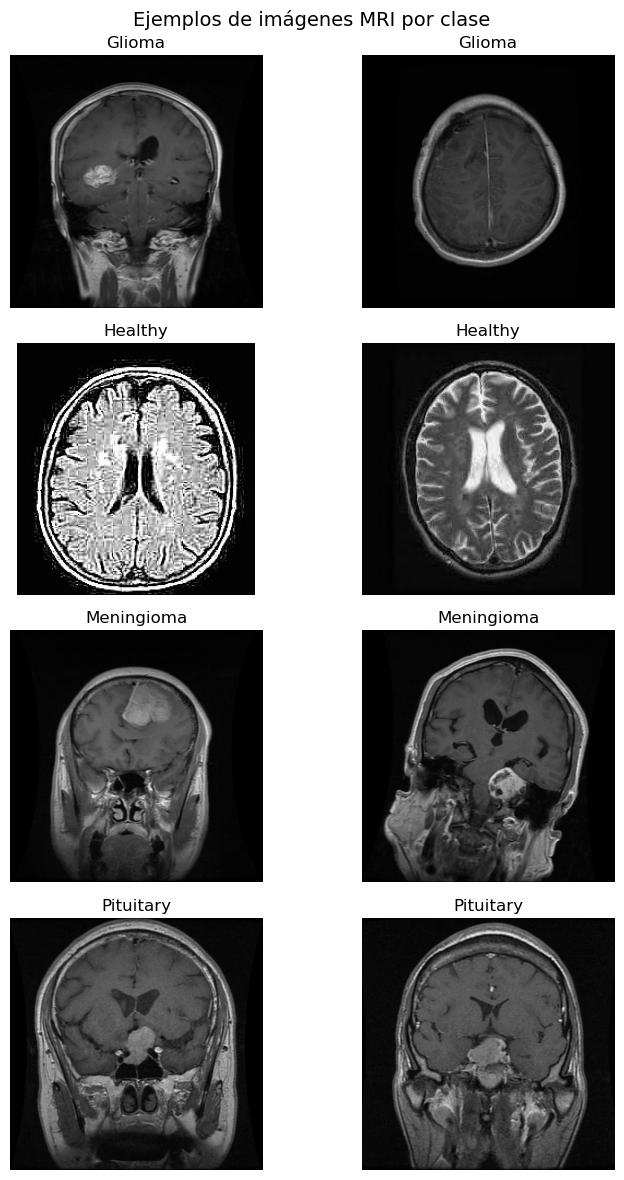

In [4]:
fig, ejes = plt.subplots(NUM_CLASES, 2, figsize=(8, 12))

for fila, clase in enumerate(CLASES):
    imagenes_clase = rutas[etiquetas == fila]
    indices = np.random.default_rng(SEED + fila).choice(
        len(imagenes_clase), size=2, replace=False
    )
    for columna, indice in enumerate(indices):
        with Image.open(imagenes_clase[indice]) as archivo:
            imagen = archivo.convert("RGB")
            ejes[fila, columna].imshow(imagen)
        ejes[fila, columna].set_title(clase.title())
        ejes[fila, columna].axis("off")

plt.suptitle("Ejemplos de imágenes MRI por clase", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Dividir el dataset en entrenamiento, validación y prueba

Separamos **70 % entrenamiento, 15 % validación y 15 % prueba**, manteniendo aproximadamente las proporciones de cada clase (`stratify`). Las imágenes de prueba **no se usan para entrenar ni escoger el modelo**.

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    rutas,
    etiquetas,
    test_size=0.30,
    random_state=SEED,
    stratify=etiquetas,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp,
)

print(f"Entrenamiento: {len(X_train)} imágenes")
print(f"Validación:    {len(X_val)} imágenes")
print(f"Prueba:        {len(X_test)} imágenes")

assert set(X_train).isdisjoint(set(X_val))
assert set(X_train).isdisjoint(set(X_test))
assert set(X_val).isdisjoint(set(X_test))

print("\nDistribución por clase:")
for i, clase in enumerate(CLASES):
    print(
        f"{clase:12s} -> train: {(y_train == i).sum():4d} "
        f"| val: {(y_val == i).sum():4d} "
        f"| test: {(y_test == i).sum():4d}"
    )

Entrenamiento: 4916 imágenes
Validación:    1053 imágenes
Prueba:        1054 imágenes

Distribución por clase:
glioma       -> train: 1135 | val:  243 | test:  243
healthy      -> train: 1400 | val:  300 | test:  300
meningioma   -> train: 1151 | val:  247 | test:  247
pituitary    -> train: 1230 | val:  263 | test:  264


## 5. Preparar las imágenes con `tf.data`

Convertimos cada imagen a **RGB**, redimensionamos a **128 × 128** píxeles y agrupamos en lotes de **32**. 

In [6]:
def cargar_imagen(ruta, etiqueta):
    contenido = tf.io.read_file(ruta)
    imagen = tf.io.decode_jpeg(contenido, channels=3)
    imagen = tf.image.resize(imagen, (IMG_SIZE, IMG_SIZE))
    imagen = tf.cast(imagen, tf.float32)
    return imagen, etiqueta


def crear_dataset(rutas_archivos, labels, entrenando=False):
    ds = tf.data.Dataset.from_tensor_slices((rutas_archivos, labels))
    if entrenando:
        ds = ds.shuffle(
            buffer_size=len(rutas_archivos),
            seed=SEED,
            reshuffle_each_iteration=True,
        )
    ds = ds.map(cargar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = crear_dataset(X_train, y_train, entrenando=True)
val_ds = crear_dataset(X_val, y_val)
test_ds = crear_dataset(X_test, y_test)

imagenes_lote, etiquetas_lote = next(iter(train_ds))
print("Dimensión del lote:", imagenes_lote.shape)
print("Etiquetas del lote:", etiquetas_lote.shape)
print("Rango de los píxeles:", float(tf.reduce_min(imagenes_lote)),
      "a", float(tf.reduce_max(imagenes_lote)))

Dimensión del lote: (32, 128, 128, 3)
Etiquetas del lote: (32,)
Rango de los píxeles: 0.0 a 255.0


## 6. Construir una CNN

La arquitectura combina cuatro bloques de **convolución + normalización + max pooling**, seguidos de una capa densa y una salida `softmax` de cuatro clases. 

In [7]:
from tensorflow.keras import layers, models

modelo = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Aumento de datos (se aplica solamente durante entrenamiento).
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.08),
    layers.Rescaling(1.0 / 255.0),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASES, activation="softmax"),
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_rotation (RandomRotation)     │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 16, 16, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             5

 Total params: 259,268 (1012.77 KB)

 Trainable params: 258,564 (1010.02 KB)

 Non-trainable params: 704 (2.75 KB)

## 7. Entrenar el modelo

Se entrenan como máximo **15 épocas**. 

In [8]:
RUTA_MODELO = DIR_RESULTADOS / "mejor_modelo_mri.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(RUTA_MODELO),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1,
    ),
]

historial = modelo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

# Para evaluar el mejor checkpoint guardado.
modelo = tf.keras.models.load_model(RUTA_MODELO)
print("Mejor modelo guardado en:", RUTA_MODELO)

Epoch 1/15


C:\Users\user\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 543ms/step - accuracy: 0.6939 - loss: 0.7499
Epoch 1: val_loss improved from None to 3.30417, saving model to C:\Users\user\OneDrive\Documents\Uniandes Maestria\Ciclo 4\Deep learning\Modulo 3\Miniproyecto 1\resultados\mejor_modelo_mri.keras

Epoch 1: finished saving model to C:\Users\user\OneDrive\Documents\Uniandes Maestria\Ciclo 4\Deep learning\Modulo 3\Miniproyecto 1\resultados\mejor_modelo_mri.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 93s 581ms/step - accuracy: 0.6939 - loss: 0.7499 - val_accuracy: 0.2498 - val_loss: 3.3042 - learning_rate: 0.0010
Epoch 2/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.7848 - loss: 0.5506
Epoch 2: val_loss improved from 3.30417 to 2.50127, saving model to C:\Users\user\OneDrive\Documents\Uniandes Maestria\Ciclo 4\Deep learning\Modulo 3\Miniproyecto 1\resultados\mejor_modelo_mri.keras

Epoch 2: finished saving model to C:\Users\user\OneDrive\Documents\Uniandes Maestria\Ciclo 4\Deep learning\Modulo 3\Miniproyecto 

## 8. Graficar la evolución del entrenamiento

Comparamos la **exactitud** y la **pérdida** de entrenamiento frente a validación para identificar señales de sobreajuste.

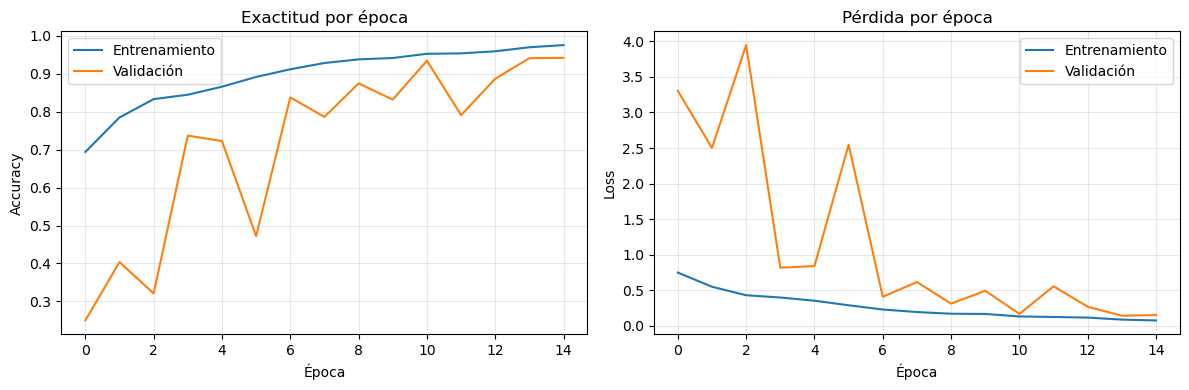

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(historial.history["accuracy"], label="Entrenamiento")
ejes[0].plot(historial.history["val_accuracy"], label="Validación")
ejes[0].set_title("Exactitud por época")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Accuracy")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

ejes[1].plot(historial.history["loss"], label="Entrenamiento")
ejes[1].plot(historial.history["val_loss"], label="Validación")
ejes[1].set_title("Pérdida por época")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Loss")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_RESULTADOS / "curvas_entrenamiento.png", dpi=150)
plt.show()

## 9. Evaluar el modelo con el conjunto de prueba

Calculamos `accuracy`, **precision**, **recall**, **F1-score** y **matriz de confusión** utilizando exclusivamente las imágenes reservadas para prueba. 

In [10]:
perdida_test, accuracy_test = modelo.evaluate(test_ds, verbose=1)
probabilidades_test = modelo.predict(test_ds, verbose=0)
predicciones_test = np.argmax(probabilidades_test, axis=1)

reporte = classification_report(
    y_test,
    predicciones_test,
    labels=np.arange(NUM_CLASES),
    target_names=CLASES,
    digits=4,
    zero_division=0,
)

print(f"Exactitud en prueba: {accuracy_test:.2%}")
print(f"Pérdida en prueba:  {perdida_test:.4f}")
print("\nReporte de clasificación:\n")
print(reporte)

texto_reporte = (
    f"Exactitud en prueba: {accuracy_test:.4f}\n"
    f"Pérdida en prueba: {perdida_test:.4f}\n\n"
    + reporte
)
(DIR_RESULTADOS / "reporte_clasificacion.txt").write_text(
    texto_reporte,
    encoding="utf-8",
)

33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - accuracy: 0.9269 - loss: 0.2005
Exactitud en prueba: 92.69%
Pérdida en prueba:  0.2005

Reporte de clasificación:

              precision    recall  f1-score   support

      glioma     0.9035    0.9630    0.9323       243
     healthy     0.9459    0.9900    0.9674       300
  meningioma     0.9447    0.7611    0.8430       247
   pituitary     0.9149    0.9773    0.9451       264

    accuracy                         0.9269      1054
   macro avg     0.9272    0.9228    0.9220      1054
weighted avg     0.9281    0.9269    0.9246      1054



489

## 10. Matriz de confusión

La diagonal contiene los aciertos de cada categoría; las celdas fuera de la diagonal muestran confusiones entre clases.

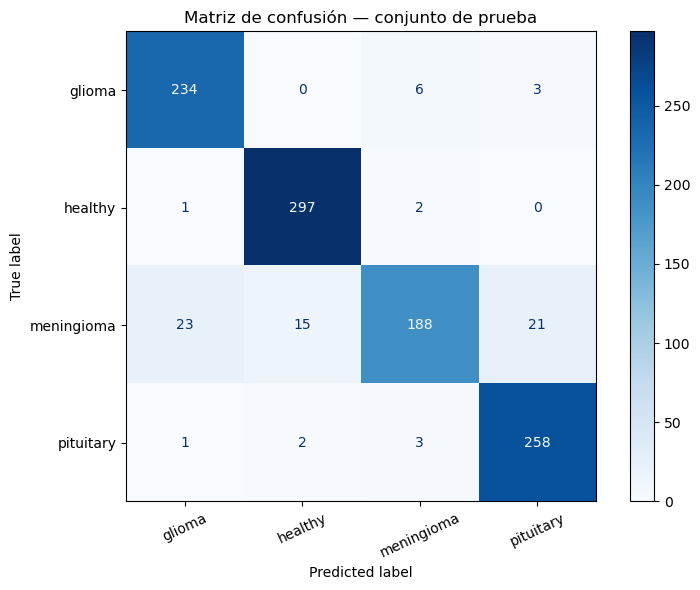

In [11]:
matriz = confusion_matrix(
    y_test,
    predicciones_test,
    labels=np.arange(NUM_CLASES),
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=CLASES,
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=True)
ax.set_title("Matriz de confusión — conjunto de prueba")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(DIR_RESULTADOS / "matriz_confusion.png", dpi=150)
plt.show()

## 11. Predicción con una imagen

Usamos una imagen del **conjunto de prueba** para comprobar el funcionamiento. 
IMPORTANTE: El porcentaje mostrado es una **puntuación del modelo**; no equivale a una probabilidad clínica de tener cáncer.

Imagen: C:\Users\user\OneDrive\Documents\Uniandes Maestria\Ciclo 4\Deep learning\Modulo 3\Miniproyecto 1\datos_mri\glioma\1014.jpg


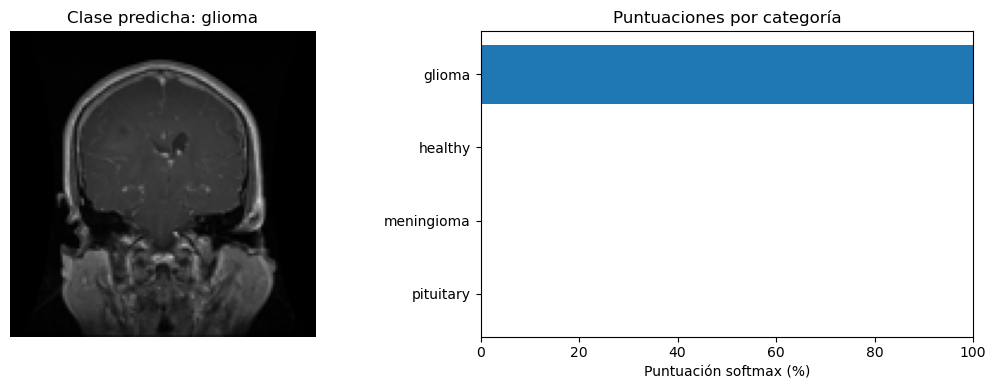

Predicción: glioma
Puntuación del modelo: 100.00%


In [12]:
RUTA_NUEVA = Path(X_test[0])  # Sustituye por otra ruta si lo deseas
print("Imagen:", RUTA_NUEVA)

with Image.open(RUTA_NUEVA) as archivo:
    imagen = archivo.convert("RGB").resize((IMG_SIZE, IMG_SIZE))

tensor = tf.keras.utils.img_to_array(imagen)[None, ...]
probabilidades = modelo.predict(tensor, verbose=0)[0]
indice_predicho = int(np.argmax(probabilidades))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].imshow(imagen)
ejes[0].set_title(f"Clase predicha: {CLASES[indice_predicho]}")
ejes[0].axis("off")

ejes[1].barh(CLASES, probabilidades * 100)
ejes[1].set_xlim(0, 100)
ejes[1].set_xlabel("Puntuación softmax (%)")
ejes[1].set_title("Puntuaciones por categoría")
ejes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"Predicción: {CLASES[indice_predicho]}")
print(f"Puntuación del modelo: {probabilidades[indice_predicho]:.2%}")